# SMARD 发电数据：EDA 画图

按顺序运行全部单元格。代码读取原始 CSV，不填补或改写数据；本 notebook 聚焦 EDA，不进行 Part 2 建模。

包含：数据概况与缺失、12 类来源趋势、日内／年度季节性、相关性与散点图、Solar 日发电量和分布变换、抽水蓄能小时规律。

**时间处理：** 文件没有时区标签。已检查的重复小时出现在德国秋季切换的 02:00，跳过小时也匹配德国规则，因此这里将原始标签解释为 `Europe/Berlin`，并保留重复小时。若下载时选择了其他时间语义，请修改参数后重新检查。

**日聚合：** 单位为 MWh。日发电量用求和；日均每小时发电量用均值。根据当地自然日计算应有的 23/24/25 小时，仅在该列当日观测完整时展示日聚合值。

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display

# 可从 mock_dataset 或其上级项目目录启动 notebook。
CSV_NAME = "Actual_generation_202001010600_202601010600_Hour.csv"
CANDIDATES = [Path("smard_data") / CSV_NAME,
              Path("mock_dataset/smard_data") / CSV_NAME]
DATA_PATH = next((p for p in CANDIDATES if p.is_file()), None)
if DATA_PATH is None:
    raise FileNotFoundError("未找到 CSV，请把 DATA_PATH 改为文件的实际路径。")
SOURCE_TIMEZONE = "Europe/Berlin"

plt.rcParams.update({
    "figure.figsize": (12, 5), "figure.dpi": 110,
    "axes.grid": True, "grid.alpha": 0.25,
    "axes.spines.top": False, "axes.spines.right": False,
})
# 图内用英文，避免本机缺少中文字体导致乱码；说明文字使用中文。


## 1. 读取、列名映射和时间检查

CSV 使用分号分隔，数字含千位逗号，`-` 表示缺失。核电的缺失与数值零保持区分。使用 Start date 标记小时，不把 End date 作为另一个数值特征。

In [3]:
raw_df = pd.read_csv(DATA_PATH, sep=";", thousands=",", na_values=["-"])
name_map = {c: c.split(" [MWh]")[0] for c in raw_df.columns[2:]}
labels = pd.to_datetime(raw_df["Start date"], format="%b %d, %Y %I:%M %p")
# 原始顺序用于推断秋季两个 02:00；无法推断时抛错，不静默删除。
local_time = labels.dt.tz_localize(
    SOURCE_TIMEZONE, ambiguous="infer", nonexistent="raise"
)
df = raw_df[list(name_map)].rename(columns=name_map).copy()
df = df.apply(pd.to_numeric, errors="raise")
df.index = pd.DatetimeIndex(local_time, name="timestamp")
df = df.sort_index()
utc_steps = df.index.tz_convert("UTC").to_series().diff().dropna()

print(f"Rows: {len(df):,}; generation variables: {df.shape[1]}")
print(f"First hour: {df.index.min()}; last hour starts: {df.index.max()}")
print(f"Duplicated source clock labels: {labels.duplicated().sum()}")
print(f"重复列名: {df.columns.duplicated().sum()}; "
      f"重复时间戳: {df.index.duplicated().sum()}; "
      f"非一小时间隔: {utc_steps.ne(pd.Timedelta(hours=1)).sum()}")
summary = pd.DataFrame({
    "dtype": df.dtypes.astype(str), "missing": df.isna().sum(),
    "missing_pct": 100 * df.isna().mean(), "zero_count": df.eq(0).sum(),
    "min_MWh": df.min(), "max_MWh": df.max(),
})
display(summary.round(2))
display(df.head())

# 为当地自然日构造完整的应有小时数，首尾部分日期不会被当完整日。
day_edges = pd.date_range(df.index.min().normalize(),
                          df.index.max().normalize() + pd.DateOffset(days=1),
                          freq="D")
expected_hours = pd.Series(
    np.diff(day_edges.tz_convert("UTC").asi8) / 3.6e12,
    index=day_edges[:-1], name="expected_hours"
)
daily_count = df.resample("D").count()
complete_day = daily_count.eq(expected_hours, axis=0)
daily_energy = df.resample("D").sum(min_count=1).where(complete_day)
daily_mean = df.resample("D").mean().where(complete_day)
print("Expected hours per local day:", expected_hours.value_counts().to_dict())


Rows: 52,608; generation variables: 12
First hour: 2020-01-01 06:00:00+01:00; last hour starts: 2026-01-01 05:00:00+01:00
Duplicated source clock labels: 6
重复列名: 0; 重复时间戳: 0; 非一小时间隔: 0


,dtype,missing,missing_pct,zero_count,min_MWh,max_MWh
Biomass,float64,0,0.00,0,3085.63,5271.25
Hydropower,float64,0,0.00,0,841.00,3082.00
Wind offshore,float64,0,0.00,35,0.00,8278.07
Wind onshore,float64,0,0.00,0,46.50,48499.50
Photovoltaics,float64,0,0.00,4221,0.00,52132.25
Other renewable,float64,0,0.00,0,56.46,244.25
Nuclear,float64,16842,32.01,6949,0.00,8204.75
Lignite,float64,0,0.00,0,1877.75,17173.25
Hard coal,float64,0,0.00,0,135.50,16393.50
Fossil gas,float64,0,0.00,0,1263.50,20146.50


,Biomass,Hydropower,Wind offshore,Wind onshore,Photovoltaics,Other renewable,Nuclear,Lignite,Hard coal,Fossil gas,Hydro pumped storage,Other conventional
timestamp,,,,,,,,,,,,
2020-01-01 06:00:00+01:00,4797.50,1333.25,1943.00,5565.50,0.00,222.75,8076.25,9338.25,2007.00,5427.75,1406.25,1736.00
2020-01-01 07:00:00+01:00,4842.25,1329.25,2154.50,5250.50,0.25,223.25,8093.00,9323.25,2012.50,5609.25,491.75,1740.75
2020-01-01 08:00:00+01:00,4886.75,1318.50,2283.25,5048.50,366.75,223.25,8097.25,9801.50,2050.00,5707.75,202.25,1743.75
2020-01-01 09:00:00+01:00,4890.50,1336.00,2341.25,5038.75,3028.50,222.00,8098.00,9961.75,2066.00,5779.25,180.75,1729.50
2020-01-01 10:00:00+01:00,4852.25,1369.00,2546.50,4775.75,6612.50,221.75,8050.75,10179.00,2045.25,5781.25,453.00,1736.25


Expected hours per local day: {24.0: 2181, 23.0: 6, 25.0: 6}


In [13]:
df

,Biomass,Hydropower,Wind offshore,Wind onshore,Photovoltaics,Other renewable,Nuclear,Lignite,Hard coal,Fossil gas,Hydro pumped storage,Other conventional
timestamp,,,,,,,,,,,,
2020-01-01 06:00:00+01:00,4797.50,1333.25,1943.00,5565.50,0.00,222.75,8076.25,9338.25,2007.00,5427.75,1406.25,1736.00
2020-01-01 07:00:00+01:00,4842.25,1329.25,2154.50,5250.50,0.25,223.25,8093.00,9323.25,2012.50,5609.25,491.75,1740.75
2020-01-01 08:00:00+01:00,4886.75,1318.50,2283.25,5048.50,366.75,223.25,8097.25,9801.50,2050.00,5707.75,202.25,1743.75
2020-01-01 09:00:00+01:00,4890.50,1336.00,2341.25,5038.75,3028.50,222.00,8098.00,9961.75,2066.00,5779.25,180.75,1729.50
2020-01-01 10:00:00+01:00,4852.25,1369.00,2546.50,4775.75,6612.50,221.75,8050.75,10179.00,2045.25,5781.25,453.00,1736.25
...,...,...,...,...,...,...,...,...,...,...,...,...
2026-01-01 01:00:00+01:00,4086.64,1109.28,4043.73,34691.29,15.14,119.45,NaN,3081.94,4449.58,5592.30,290.59,1834.34
2026-01-01 02:00:00+01:00,4017.82,1036.43,4889.69,35449.62,15.06,120.10,NaN,2815.75,4517.20,4855.01,131.48,1801.83
2026-01-01 03:00:00+01:00,3982.95,978.29,5394.41,36594.04,16.13,120.51,NaN,2344.65,4429.11,4498.88,224.98,1832.08


## 2. 缺失值随时间的分布

观察缺失是否集中在特定年份／变量；不要仅凭图把核电的缺失改成零。

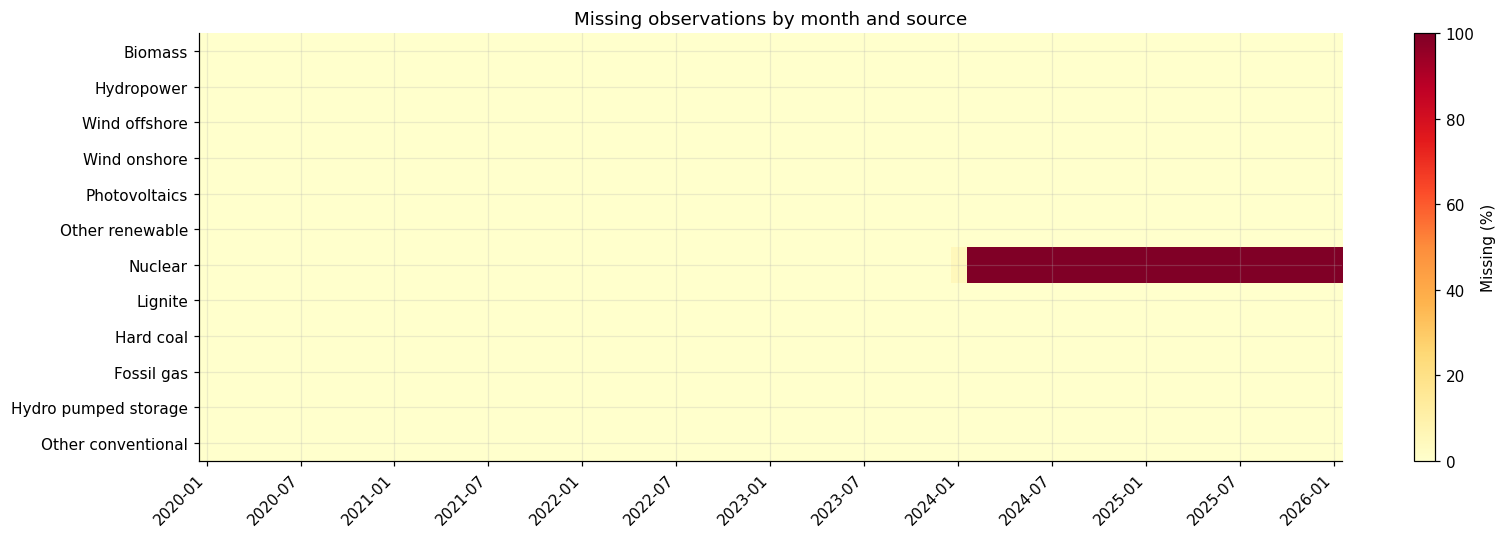

In [15]:
monthly_missing = df.isna().resample("MS").mean().T * 100
fig, ax = plt.subplots(figsize=(15, 5))
im = ax.imshow(monthly_missing.to_numpy(), aspect="auto", cmap="YlOrRd",
               vmin=0, vmax=100, interpolation="nearest")
ax.set_yticks(range(len(df.columns)), labels=df.columns)
positions = np.arange(0, monthly_missing.shape[1], 6)
ax.set_xticks(positions, labels=monthly_missing.columns[positions].strftime("%Y-%m"),
              rotation=45, ha="right")
ax.set_title("Missing observations by month and source")
fig.colorbar(im, ax=ax, label="Missing (%)")
fig.tight_layout()
plt.show()


## 3. 各来源长期趋势

细线是完整日的平均每小时发电量，粗线是其后向 30 日均值（至少 15 个有效日）。各子图使用独立纵轴，不可仅凭线条高度比较绝对规模。缺失不会填零。

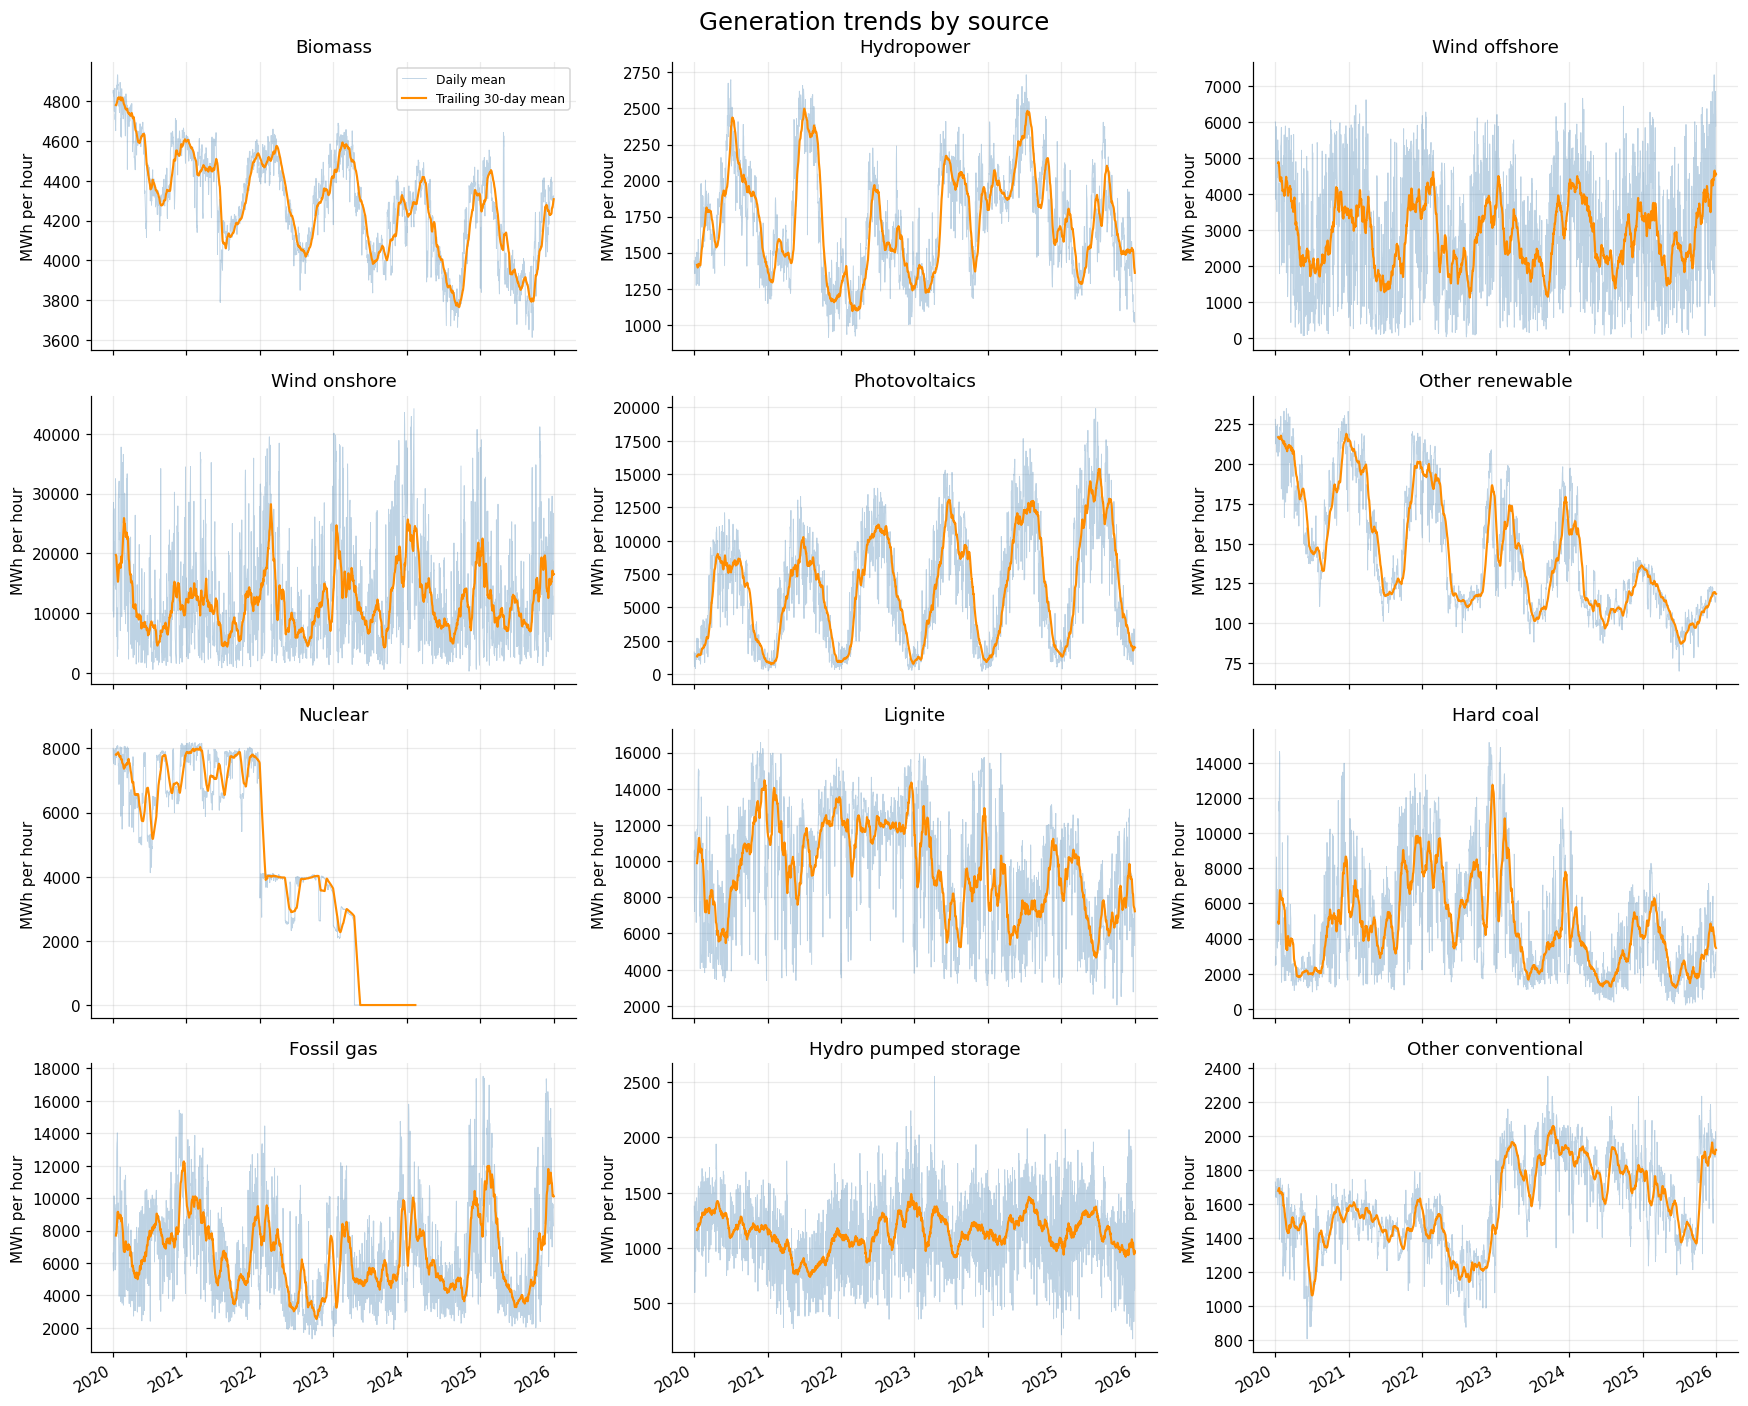

In [ ]:
fig, axes = plt.subplots(4, 3, figsize=(16, 13), sharex=True)
for ax, col in zip(axes.flat, df.columns):
    ax.plot(daily_mean.index, daily_mean[col], color="steelblue",
            alpha=0.35, linewidth=0.6, label="Daily mean")
    smooth = daily_mean[col].rolling(30, min_periods=15).mean()
    ax.plot(smooth.index, smooth, color="darkorange", linewidth=1.4,
            label="Trailing 30-day mean")
    ax.set_title(col)
    ax.set_ylabel("MWh per hour")
axes[0, 0].legend(fontsize=8)
fig.suptitle("Generation trends by source", fontsize=16)
fig.autofmt_xdate()
fig.tight_layout()
plt.show()

## 4. 季节性：月份与小时

这是跨年份合并的描述性均值，可能混合装机趋势、制度变化和季节性。核电等变量的有效年份覆盖不同，不能把曲线直接视为稳定规律。

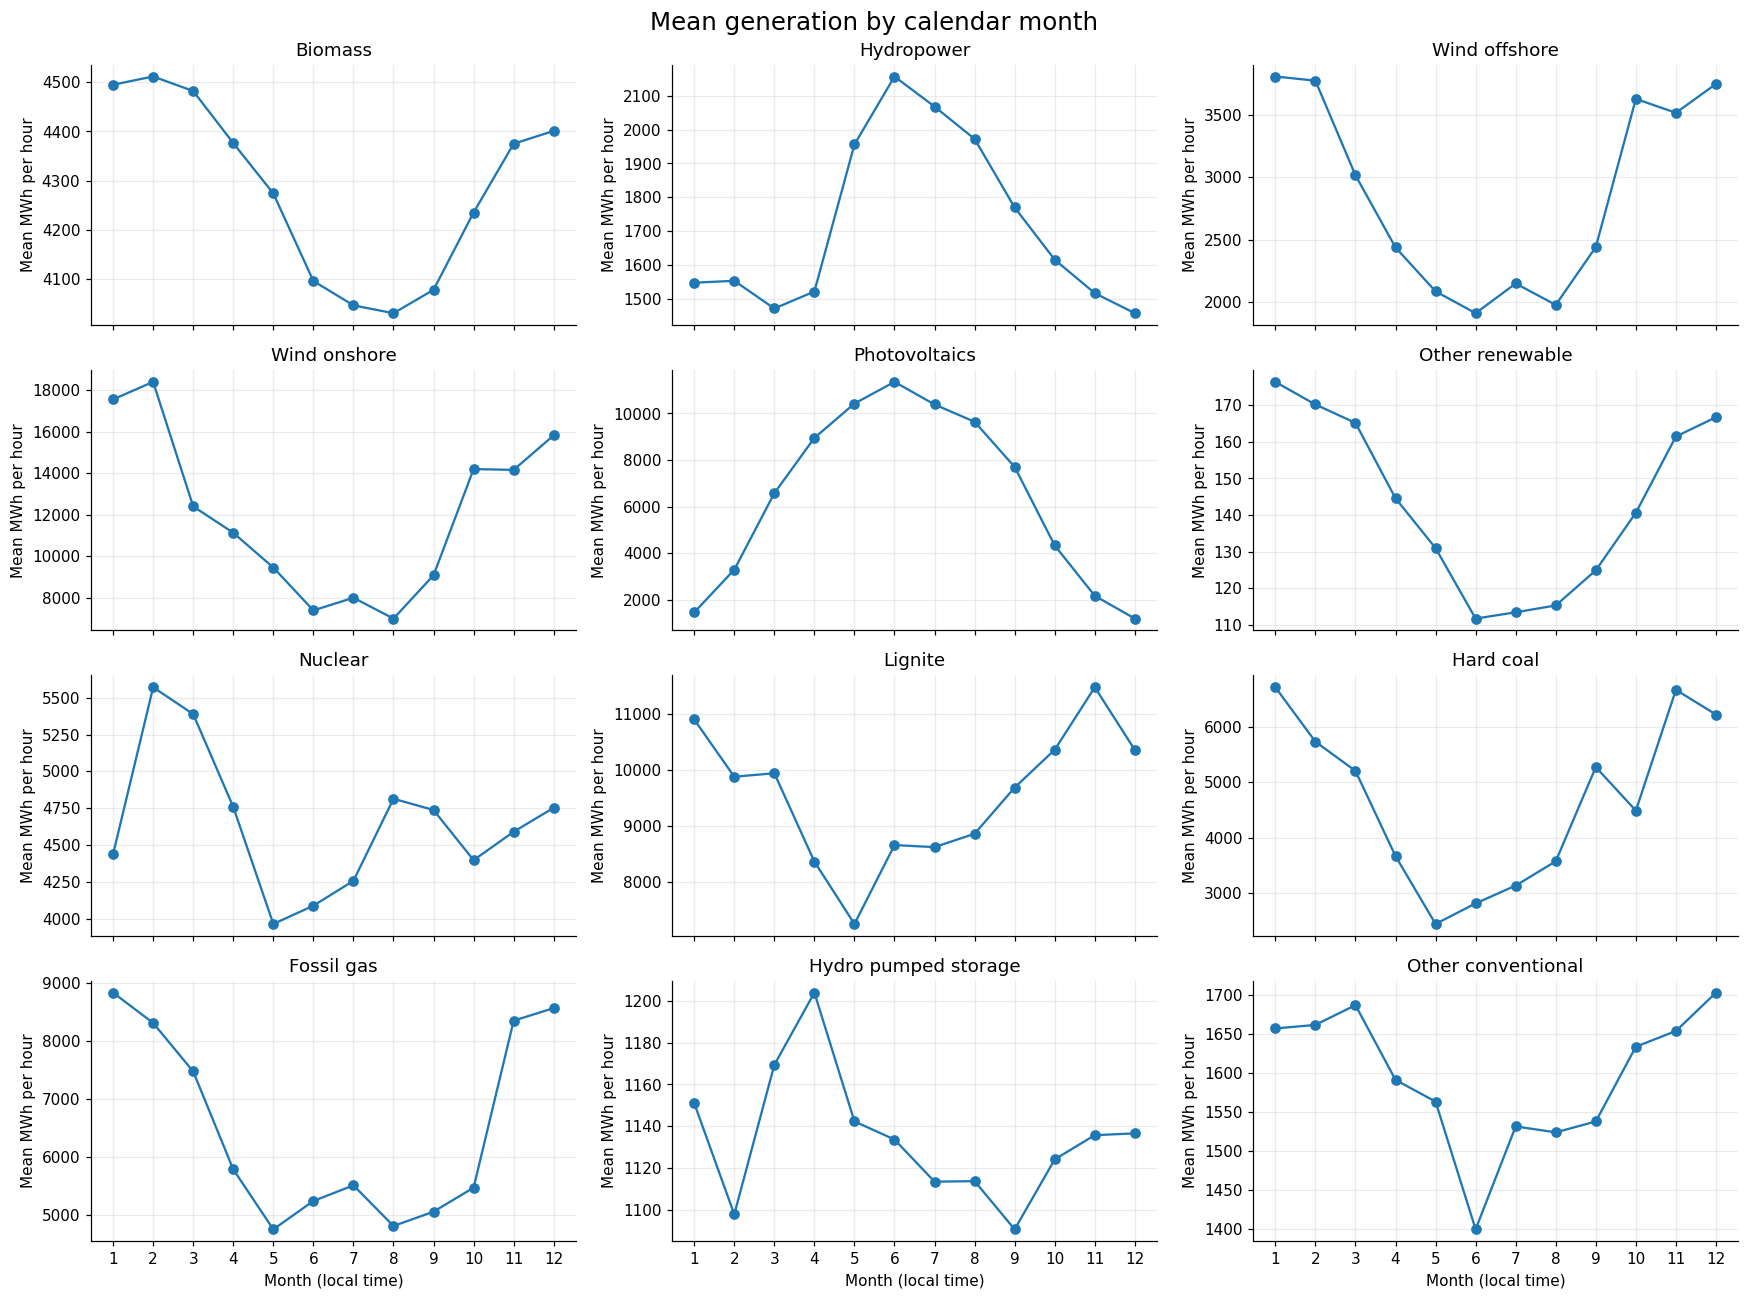

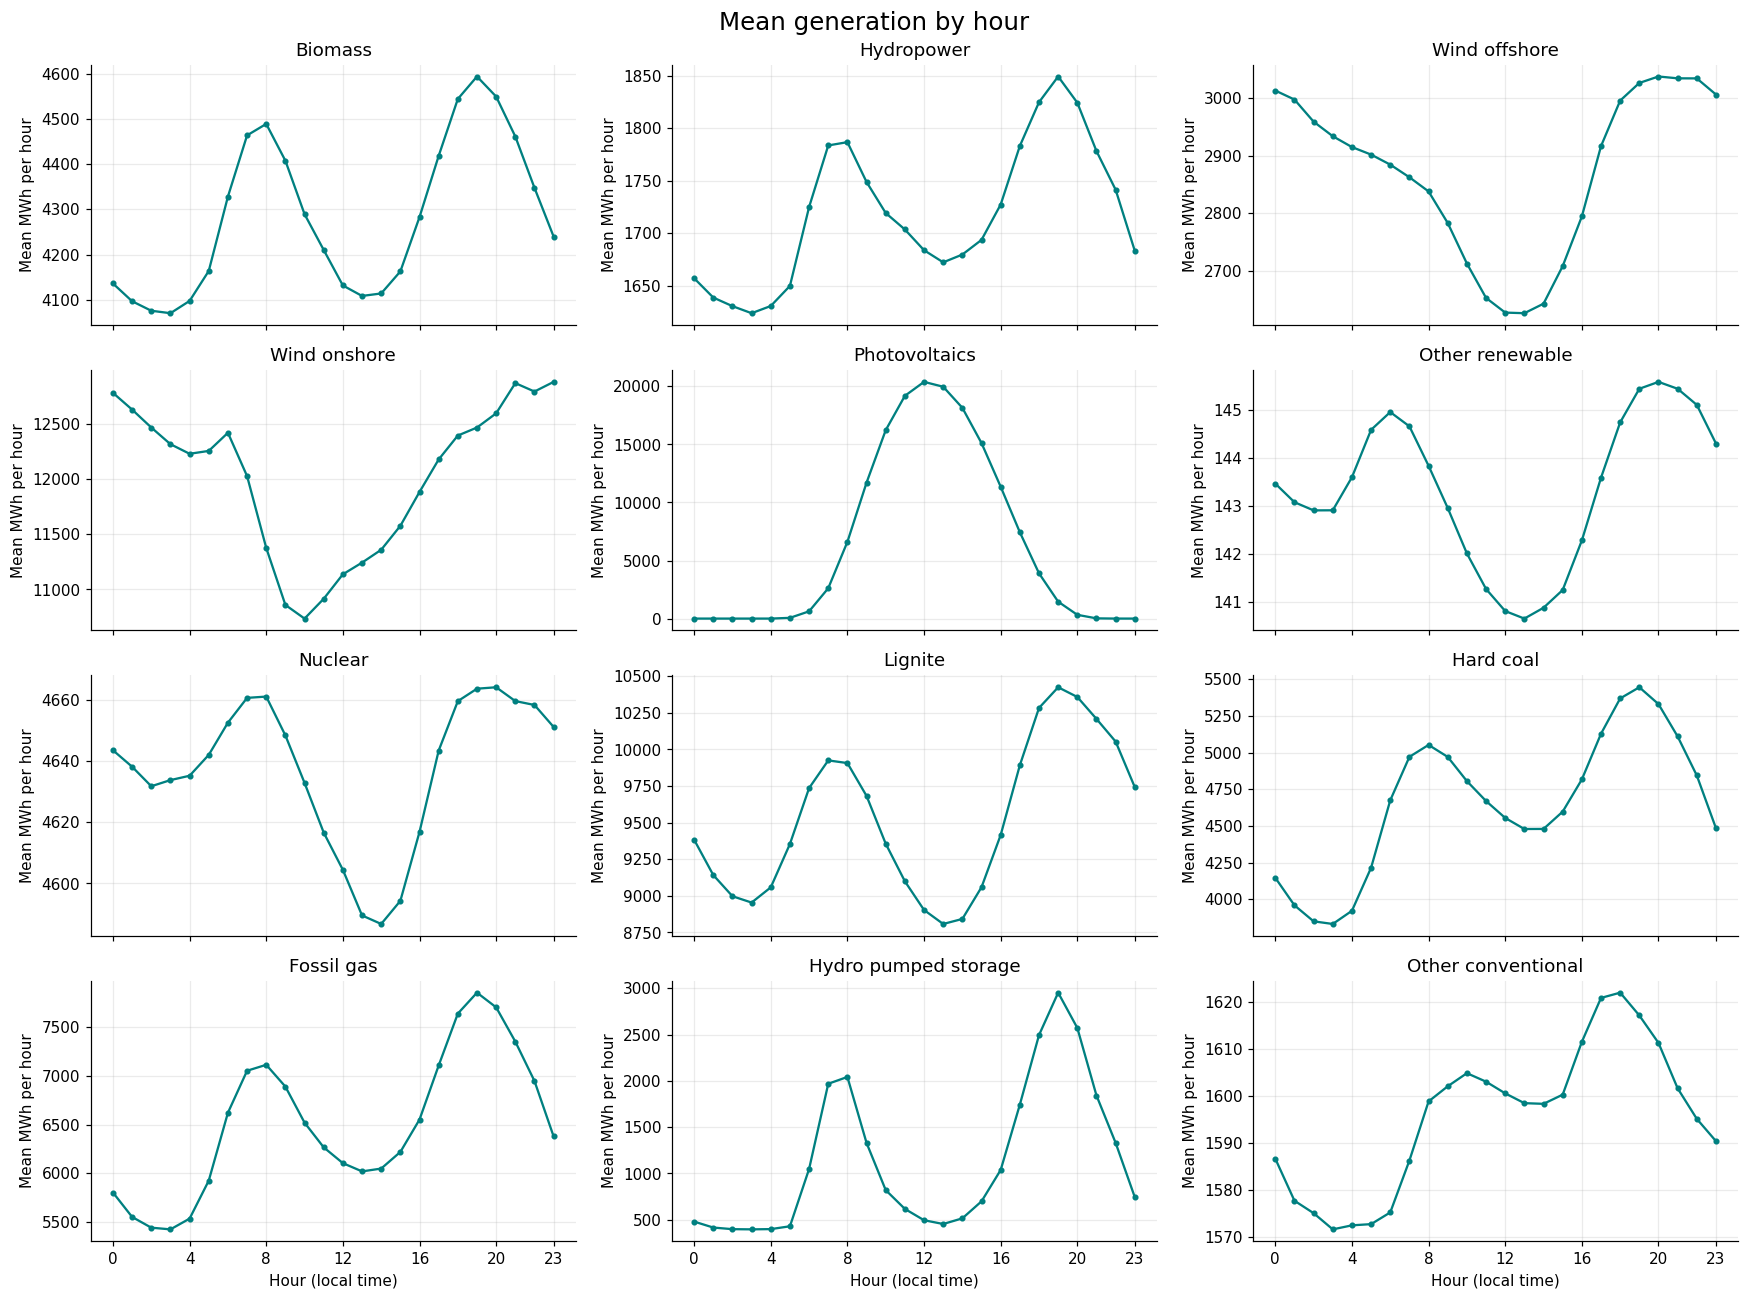

In [ ]:
fig, axes = plt.subplots(4, 3, figsize=(16, 12), sharex=True)
monthly_pattern = df.groupby(df.index.month).mean()
for ax, col in zip(axes.flat, df.columns):
    ax.plot(monthly_pattern.index, monthly_pattern[col], marker="o")
    ax.set_title(col)
    ax.set_xticks(range(1, 13))
    ax.set_ylabel("Mean MWh per hour")
for ax in axes[-1]:
    ax.set_xlabel("Month (local time)")
fig.suptitle("Mean generation by calendar month", fontsize=16)
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(4, 3, figsize=(16, 12), sharex=True)
hourly_pattern = df.groupby(df.index.hour).mean()
for ax, col in zip(axes.flat, df.columns):
    ax.plot(hourly_pattern.index, hourly_pattern[col], marker=".", color="teal")
    ax.set_title(col)
    ax.set_xticks([0, 4, 8, 12, 16, 20, 23])
    ax.set_ylabel("Mean MWh per hour")
for ax in axes[-1]:
    ax.set_xlabel("Hour (local time)")
fig.suptitle("Mean generation by hour", fontsize=16)
fig.tight_layout()
plt.show()

## 5. 变量相关性与散点图

Pearson 相关系数使用成对非缺失观测，覆盖范围可能不同。高相关不等于确定性线性关系，也不能解释成因果；若怀疑共线，还需要跨时段验证线性残差。散点仅抽样展示，相关系数基于全部成对有效观测。

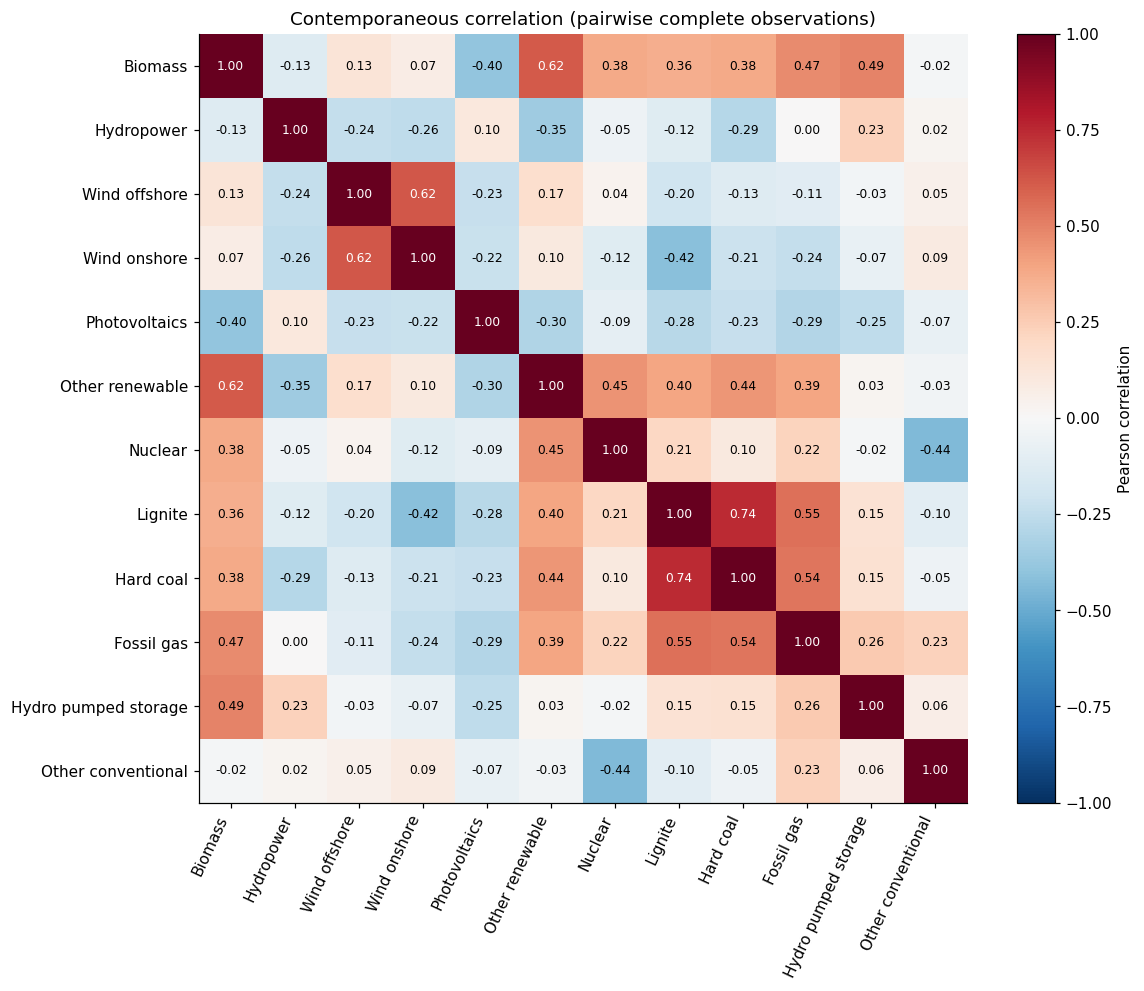

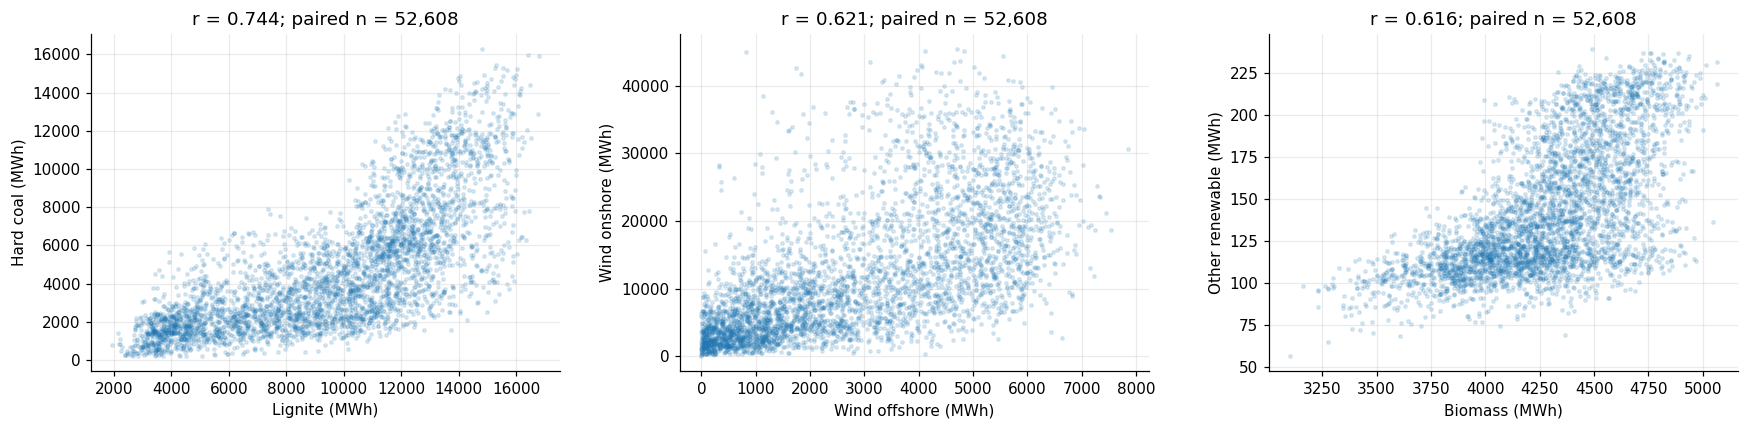

In [ ]:
corr = df.corr(min_periods=100)
fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.grid(False)
ax.set_xticks(range(len(corr)), labels=corr.columns, rotation=65, ha="right")
ax.set_yticks(range(len(corr)), labels=corr.index)
for i in range(len(corr)):
    for j in range(len(corr)):
        value = corr.iloc[i, j]
        ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(value) > 0.6 else "black")
fig.colorbar(im, ax=ax, label="Pearson correlation")
ax.set_title("Contemporaneous correlation (pairwise complete observations)")
fig.tight_layout()
plt.show()

pairs = [(a, b, corr.loc[a, b]) for i, a in enumerate(df.columns)
         for b in df.columns[i+1:] if pd.notna(corr.loc[a, b])]
pairs = sorted(pairs, key=lambda x: abs(x[2]), reverse=True)[:3]
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (a, b, r) in zip(axes, pairs):
    pair = df[[a, b]].dropna()
    sample = pair.sample(n=min(4000, len(pair)), random_state=42)
    ax.scatter(sample[a], sample[b], s=5, alpha=0.15)
    ax.set(xlabel=f"{a} (MWh)", ylabel=f"{b} (MWh)",
           title=f"r = {r:.3f}; paired n = {len(pair):,}")
fig.tight_layout()
plt.show()

## 6. Solar：日发电量、月份分布和正态性

日总电量仅保留观测完整的当地自然日；23/25 小时日保留真实日总量。Q–Q 图用于观察分布形状，不代表独立性或预测有效性。

Solar 完整日数量: 2,191


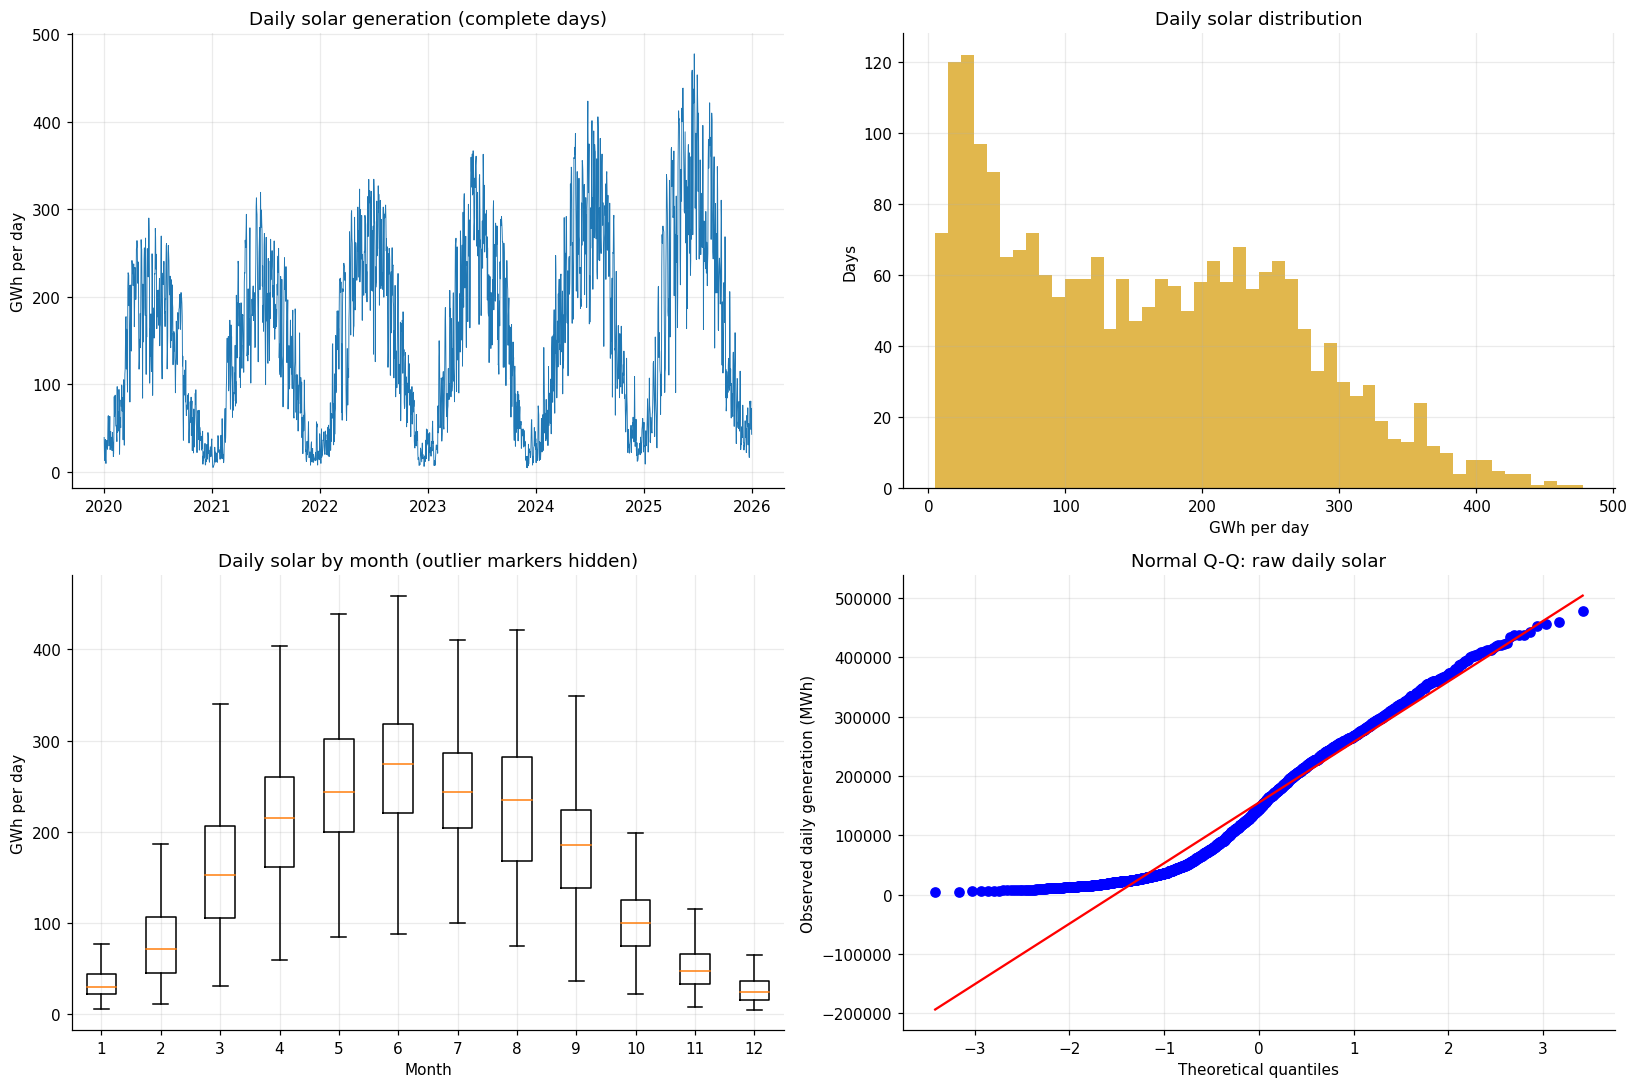

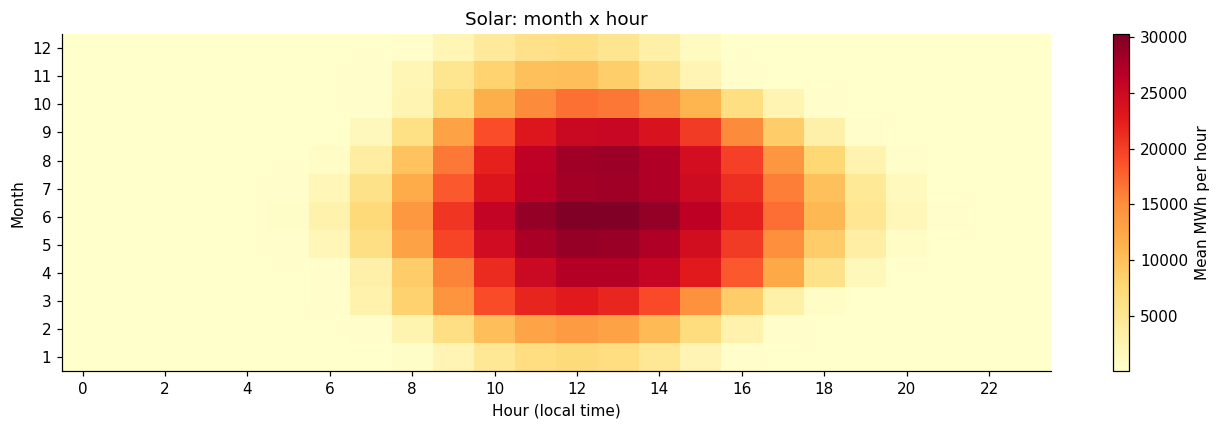

In [16]:
solar_daily = daily_energy["Photovoltaics"].dropna()
print(f"Solar 完整日数量: {len(solar_daily):,}")
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
axes[0, 0].plot(solar_daily.index, solar_daily / 1000, linewidth=0.6)
axes[0, 0].set(title="Daily solar generation (complete days)", ylabel="GWh per day")
axes[0, 1].hist(solar_daily / 1000, bins=50, color="goldenrod", alpha=0.8)
axes[0, 1].set(title="Daily solar distribution", xlabel="GWh per day", ylabel="Days")
month_groups = [solar_daily[solar_daily.index.month == m].to_numpy() / 1000
                for m in range(1, 13)]
axes[1, 0].boxplot(month_groups, showfliers=False)
axes[1, 0].set(title="Daily solar by month (outlier markers hidden)",
               xlabel="Month", ylabel="GWh per day")
stats.probplot(solar_daily.to_numpy(), dist="norm", plot=axes[1, 1])
axes[1, 1].set_title("Normal Q-Q: raw daily solar")
axes[1, 1].set_ylabel("Observed daily generation (MWh)")
fig.tight_layout()
plt.show()

solar_heatmap = df["Photovoltaics"].groupby(
    [df.index.month, df.index.hour]
).mean().unstack()
fig, ax = plt.subplots(figsize=(12, 4))
im = ax.imshow(solar_heatmap, aspect="auto", origin="lower", cmap="YlOrRd")
ax.grid(False)
ax.set_xticks(range(0, 24, 2), labels=range(0, 24, 2))
ax.set_yticks(range(12), labels=range(1, 13))
ax.set(xlabel="Hour (local time)", ylabel="Month", title="Solar: month x hour")
fig.colorbar(im, ax=ax, label="Mean MWh per hour")
fig.tight_layout()
plt.show()


## 7. Solar 去趋势／季节性与分布变换（可选延伸）

用线性趋势和三阶年度 Fourier 项拟合描述性均值，再看残差及 Yeo–Johnson 变换后的残差。该方法是一个可解释的初步尝试，不保证正态，也不证明趋势形式正确。

**这里只做全样本 EDA。若用于预测或填补验证，趋势、季节性与变换参数必须在每个训练集内估计。** z-score 本身不会改变分布形状。

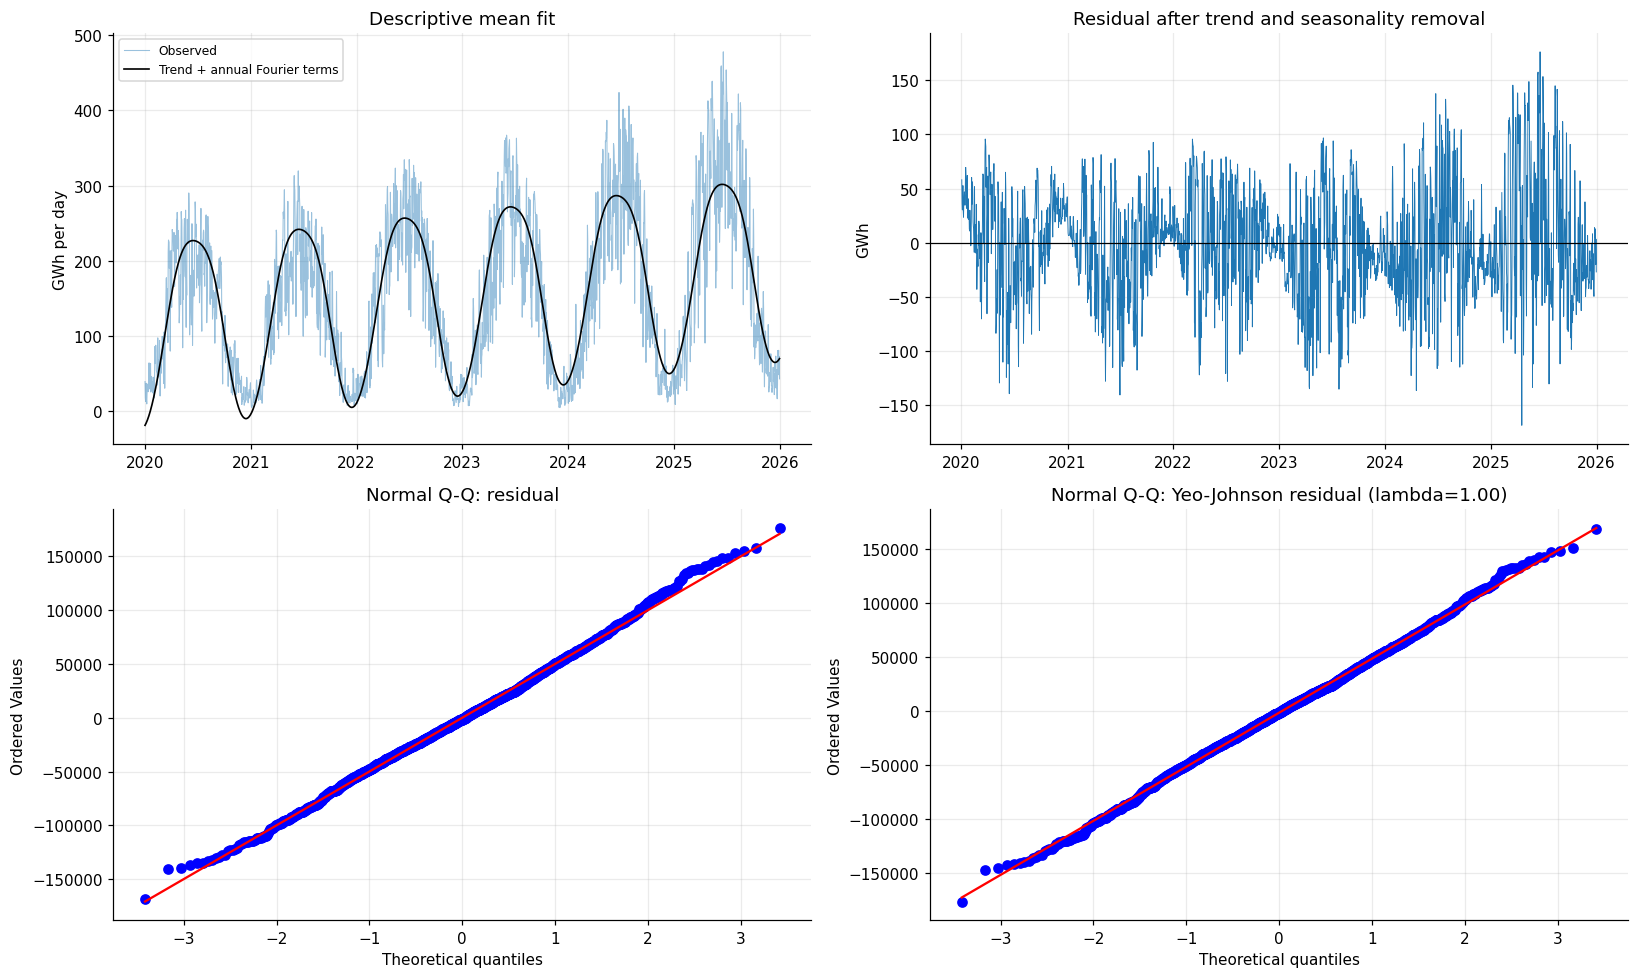

,series,skewness,excess_kurtosis
0,Raw daily solar,0.412,-0.761
1,Residual,0.112,0.169
2,Yeo-Johnson residual,0.002,0.150


In [17]:
elapsed_days = (solar_daily.index.tz_localize(None) -
                solar_daily.index[0].tz_localize(None)).days.to_numpy()
t = elapsed_days / 365.2425
features = [np.ones(len(t)), t]
for k in range(1, 4):
    features.extend([np.sin(2 * np.pi * k * t), np.cos(2 * np.pi * k * t)])
X_season = np.column_stack(features)
beta = np.linalg.lstsq(X_season, solar_daily.to_numpy(), rcond=None)[0]
fitted = X_season @ beta
residual = solar_daily.to_numpy() - fitted
transformed, yj_lambda = stats.yeojohnson(residual)

fig, axes = plt.subplots(2, 2, figsize=(15, 9))
axes[0, 0].plot(solar_daily.index, solar_daily / 1000, alpha=0.45,
                linewidth=0.7, label="Observed")
axes[0, 0].plot(solar_daily.index, fitted / 1000, color="black",
                linewidth=1.1, label="Trend + annual Fourier terms")
axes[0, 0].set(title="Descriptive mean fit", ylabel="GWh per day")
axes[0, 0].legend(fontsize=8)
axes[0, 1].plot(solar_daily.index, residual / 1000, linewidth=0.6)
axes[0, 1].axhline(0, color="black", linewidth=0.8)
axes[0, 1].set(title="Residual after trend and seasonality removal", ylabel="GWh")
stats.probplot(residual, dist="norm", plot=axes[1, 0])
axes[1, 0].set_title("Normal Q-Q: residual")
stats.probplot(transformed, dist="norm", plot=axes[1, 1])
axes[1, 1].set_title(f"Normal Q-Q: Yeo-Johnson residual (lambda={yj_lambda:.2f})")
fig.tight_layout()
plt.show()
display(pd.DataFrame({
    "series": ["Raw daily solar", "Residual", "Yeo-Johnson residual"],
    "skewness": [stats.skew(v) for v in [solar_daily, residual, transformed]],
    "excess_kurtosis": [stats.kurtosis(v) for v in [solar_daily, residual, transformed]],
}).round(3))


## 8. 抽水蓄能：小时规律与季节差异

左图比较工作日和周末的均值、中位数与四分位区间；右图展示月份 × 小时均值。当前只有发电侧，没有抽水耗电和电价，不能仅凭这些图推断实际套利利润。

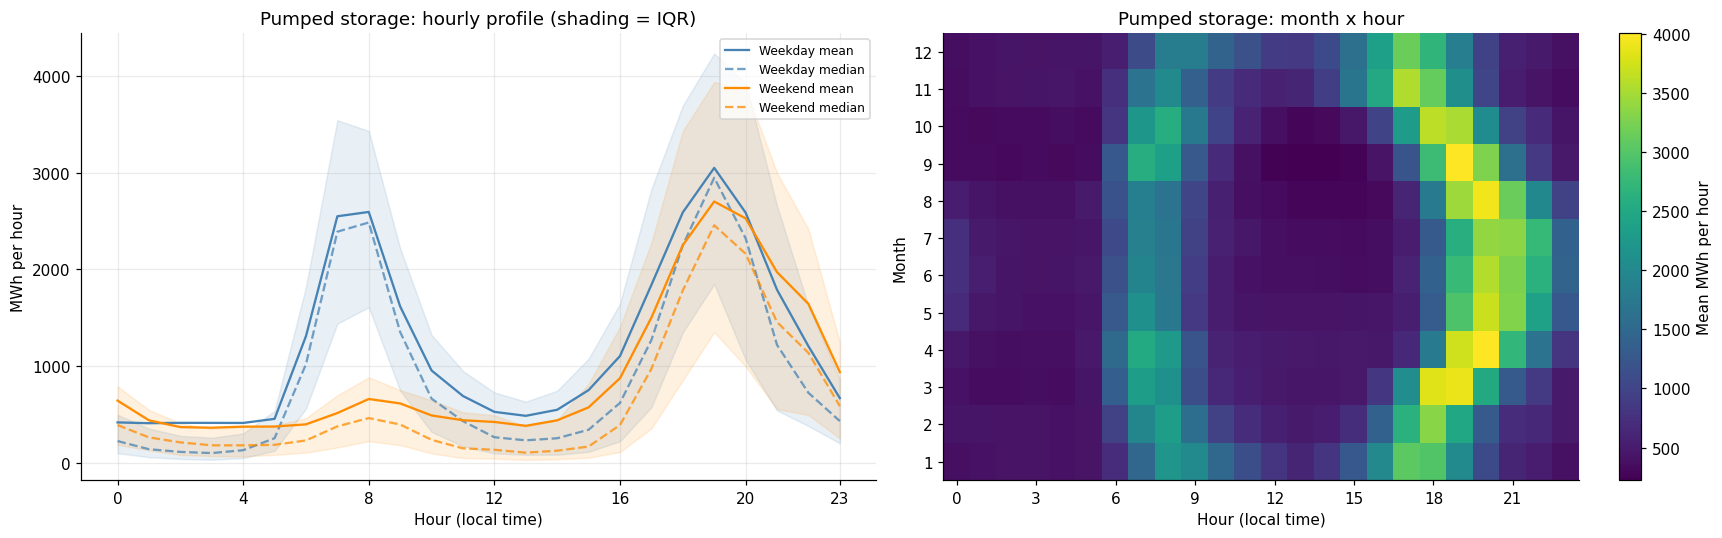

In [18]:
pump = df["Hydro pumped storage"]
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for label, mask, color in [
    ("Weekday", df.index.dayofweek < 5, "steelblue"),
    ("Weekend", df.index.dayofweek >= 5, "darkorange"),
]:
    values = pump.loc[mask]
    grouped = values.groupby(values.index.hour)
    mean, median = grouped.mean(), grouped.median()
    lower, upper = grouped.quantile(0.25), grouped.quantile(0.75)
    axes[0].plot(mean.index, mean, color=color, label=f"{label} mean")
    axes[0].plot(median.index, median, color=color, linestyle="--",
                 alpha=0.75, label=f"{label} median")
    axes[0].fill_between(lower.index, lower.to_numpy(), upper.to_numpy(),
                         color=color, alpha=0.12)
axes[0].set(title="Pumped storage: hourly profile (shading = IQR)",
            xlabel="Hour (local time)", ylabel="MWh per hour")
axes[0].set_xticks([0, 4, 8, 12, 16, 20, 23])
axes[0].legend(fontsize=8)
heat = pump.groupby([pump.index.month, pump.index.hour]).mean().unstack()
im = axes[1].imshow(heat, aspect="auto", origin="lower", cmap="viridis")
axes[1].grid(False)
axes[1].set_xticks(range(0, 24, 3), labels=range(0, 24, 3))
axes[1].set_yticks(range(12), labels=range(1, 13))
axes[1].set(title="Pumped storage: month x hour", xlabel="Hour (local time)", ylabel="Month")
fig.colorbar(im, ax=axes[1], label="Mean MWh per hour")
fig.tight_layout()
plt.show()


## 看图后填写的结论

- 哪些来源有明显长期变化？是否出现结构性变化？
- Solar 的月／小时模式是什么？日总量是否接近正态？处理后还有哪些偏离？
- 抽水蓄能工作日与周末的模式有何不同？不同季节是否稳定？
- 缺失值是否集中在某个变量和时期？
- 哪些变量相关较强？是否需要进一步验证确定性关系，而不只看相关系数？

当前文件没有直接命名为 Thermal 或 Garbage 的列；本 notebook 不擅自构造这些目标。原始数值缺失保持缺失，未进行 imputation。

In [6]:
df.columns

Index(['Biomass', 'Hydropower', 'Wind offshore', 'Wind onshore',
       'Photovoltaics', 'Other renewable', 'Nuclear', 'Lignite', 'Hard coal',
       'Fossil gas', 'Hydro pumped storage', 'Other conventional'],
      dtype='object')

In [7]:
df.index

DatetimeIndex(['2020-01-01 06:00:00+01:00', '2020-01-01 07:00:00+01:00',
               '2020-01-01 08:00:00+01:00', '2020-01-01 09:00:00+01:00',
               '2020-01-01 10:00:00+01:00', '2020-01-01 11:00:00+01:00',
               '2020-01-01 12:00:00+01:00', '2020-01-01 13:00:00+01:00',
               '2020-01-01 14:00:00+01:00', '2020-01-01 15:00:00+01:00',
               ...
               '2025-12-31 20:00:00+01:00', '2025-12-31 21:00:00+01:00',
               '2025-12-31 22:00:00+01:00', '2025-12-31 23:00:00+01:00',
               '2026-01-01 00:00:00+01:00', '2026-01-01 01:00:00+01:00',
               '2026-01-01 02:00:00+01:00', '2026-01-01 03:00:00+01:00',
               '2026-01-01 04:00:00+01:00', '2026-01-01 05:00:00+01:00'],
              dtype='datetime64[ns, Europe/Berlin]', name='timestamp', length=52608, freq=None)

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import RobustScaler


def preprocess_power_data(df_input):
    df = df_input.copy()

    print("--- 开始数据预处理 ---")

    # ==========================================
    # 1. 时序对齐与缺失值处理 (Resampling & Imputation)
    # ==========================================
    # 确保时序完全连续，自动补齐可能缺失的夏令时切换小时
    df = df.resample("1h").asfreq()

    # 电力数据具有很强的时序相关性，使用前后邻近值进行线性插值，填补少量缺失值
    energy_cols = df.columns
    df[energy_cols] = df[energy_cols].interpolate(method="linear")
    # 如果开头结尾有缺失，用最近的值填补
    df[energy_cols] = df[energy_cols].bfill().ffill()

    # ==========================================
    # 2. 核心特征工程：提取多重时间周期 (Time Features)
    # ==========================================
    # 提取小时、星期、月份特征
    df["hour"] = df.index.hour
    df["dayofweek"] = df.index.dayofweek
    df["month"] = df.index.month
    df["year"] = df.index.year

    # 周期性特征的环形编码 (Cyclic Encoding)
    # 避免模型把 23点 和 0点、12月 和 1月 识别为极端的两个值
    df["hour_sin"] = np.sin(2 * np.pi * df["hour"] / 24.0)
    df["hour_cos"] = np.cos(2 * np.pi * df["hour"] / 24.0)
    df["month_sin"] = np.sin(2 * np.pi * (df["month"] - 1) / 12.0)
    df["month_cos"] = np.cos(2 * np.pi * (df["month"] - 1) / 12.0)

    # 判断是否为周末 (周末工业用电量低，会直接影响调峰传统能源的出力)
    df["is_weekend"] = (df["dayofweek"] >= 5).astype(int)

    # ==========================================
    # 3. 针对德国核能政策的定向处理 (Nuclear Shock)
    # ==========================================
    # 2023年4月以后德国核电归零。为防止历史高位核电数据误导模型，建立突变标签
    # 1 表示有核电时期，0 表示无核电时期
    df["nuclear_era"] = (df.index < "2023-04-16 00:00:00+01:00").astype(int)

    # ==========================================
    # 4. 构建历史追踪与滑动窗口特征 (Lag & Rolling Features)
    # ==========================================
    # 针对风电(Wind onshore/offshore)和光伏(Photovoltaics)等高波动电源构建
    volatile_sources = ["Wind onshore", "Wind offshore", "Photovoltaics"]

    for col in volatile_sources:
        if col in df.columns:
            # 滞后特征 (Lags): 看过去 1 小时、2 小时、24 小时的出力情况
            df[f"{col}_lag_1h"] = df[col].shift(1)
            df[f"{col}_lag_2h"] = df[col].shift(2)
            df[f"{col}_lag_24h"] = df[col].shift(24)

            # 滑动窗口统计量 (Rolling): 过去 4 小时和 24 小时的平均出力与标准差
            # closed='left' 避免引入未来数据 (Data Leakage)
            df[f"{col}_roll_mean_4h"] = (
                df[col].shift(1).rolling(window=4).mean()
            )
            df[f"{col}_roll_std_4h"] = df[col].shift(1).rolling(window=4).std()
            df[f"{col}_roll_mean_24h"] = (
                df[col].shift(1).rolling(window=24).mean()
            )

    # ==========================================
    # 5. 构建“系统净负荷”与协同特征 (System Synergy)
    # ==========================================
    # 化石能源(Gas/Coal)和抽水蓄能通常在风光出力低时补位，高时停机
    if "Wind onshore" in df.columns and "Photovoltaics" in df.columns:
        df["total_wind_solar"] = (
            df["Wind onshore"] + df.get("Wind offshore", 0) + df["Photovoltaics"]
        )
        # 计算风光总出力的变化率 (衡量电网调峰压力的指标)
        df["wind_solar_diff_1h"] = df["total_wind_solar"].diff(1)

    # 清洗由于 Shift 产生的初始几行的 NaN 值
    df = df.dropna()

    print(f"--- 预处理完成，当前数据维度: {df.shape} ---")
    return df


# ==========================================
# 6. 数据标准化 (Scaling)
# ==========================================
# 针对风电等有极端毛刺/突发峰值的数据，使用 RobustScaler 避免异常值对模型的影响
def scale_features(df, target_cols):
    scaler = RobustScaler()
    df_scaled = df.copy()
    df_scaled[target_cols] = scaler.fit_transform(df[target_cols])
    return df_scaled, scaler


In [12]:
df_processed = preprocess_power_data(df)

--- 开始数据预处理 ---
--- 预处理完成，当前数据维度: (52584, 42) ---


<Axes: title={'center': 'Solar after removing annual seasonality'}, xlabel='timestamp'>

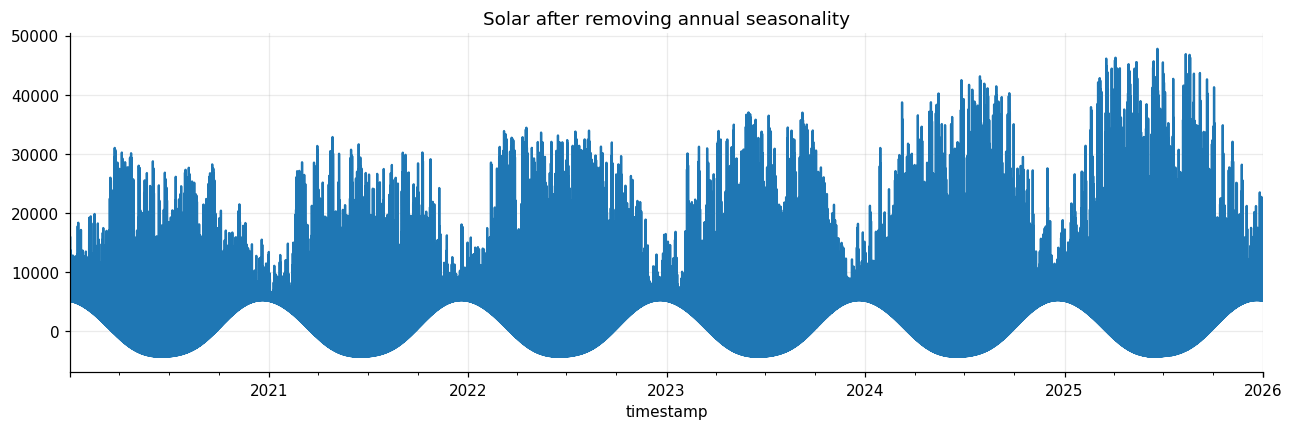

In [17]:
# 使用 notebook 中已有的完整日 Solar 发电量，单位 MWh
solar = df["Photovoltaics"]

# 按时间排序，前 80% 用于估计季节模板
split = int(len(solar) * 0.8)
solar_train = solar.iloc[:split]

# 用连续时间构造年度周期，闰年也能自然处理
origin = solar.index[0].tz_localize(None)

def annual_design(index, harmonics=3):
    dates = index.tz_localize(None)
    t = np.asarray(
        (dates - origin).total_seconds() / 86400 / 365.2425
    )
    columns = [np.ones(len(t)), t]  # 截距和长期趋势

    for k in range(1, harmonics + 1):
        columns.append(np.sin(2 * np.pi * k * t))
        columns.append(np.cos(2 * np.pi * k * t))

    return np.column_stack(columns)

X_train = annual_design(solar_train.index)
beta = np.linalg.lstsq(X_train, solar_train.to_numpy(), rcond=None)[0]

X_all = annual_design(solar.index)

# 只减掉年度周期部分，保留长期趋势和平均水平
seasonal_solar = X_all[:, 2:] @ beta[2:]
solar_deseasonalized = pd.Series(
    solar.to_numpy() - seasonal_solar,
    index=solar.index,
    name="solar_deseasonalized",
)

solar_deseasonalized.plot(figsize=(14, 4),
                          title="Solar after removing annual seasonality")

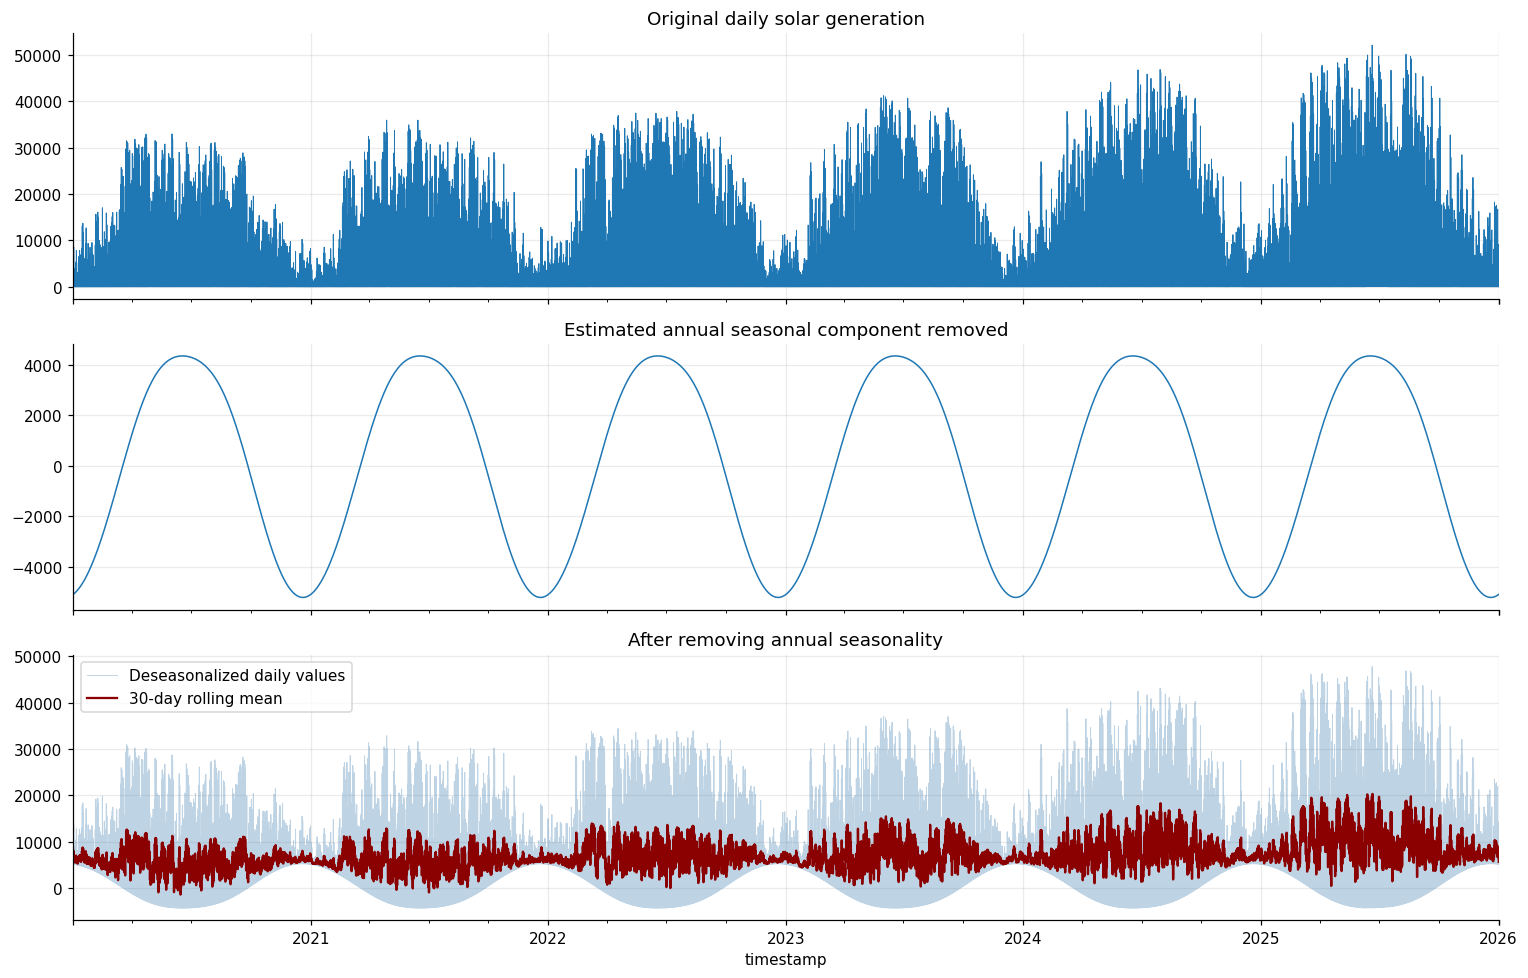

In [18]:
seasonal_component = pd.Series(
    seasonal_solar,
    index=solar.index,
    name="estimated_annual_seasonality",
)

fig, axes = plt.subplots(3, 1, figsize=(14, 9), sharex=True)

solar.plot(
    ax=axes[0],
    linewidth=0.6,
    title="Original daily solar generation",
)
seasonal_component.plot(
    ax=axes[1],
    linewidth=1,
    title="Estimated annual seasonal component removed",
)
solar_deseasonalized.plot(
    ax=axes[2],
    color="steelblue",
    alpha=0.35,
    linewidth=0.6,
    label="Deseasonalized daily values",
)
solar_deseasonalized.rolling(
    30, center=True, min_periods=15
).mean().plot(
    ax=axes[2],
    color="darkred",
    linewidth=1.5,
    label="30-day rolling mean",
)
axes[2].set_title("After removing annual seasonality")
axes[2].legend()

for ax in axes:
    ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

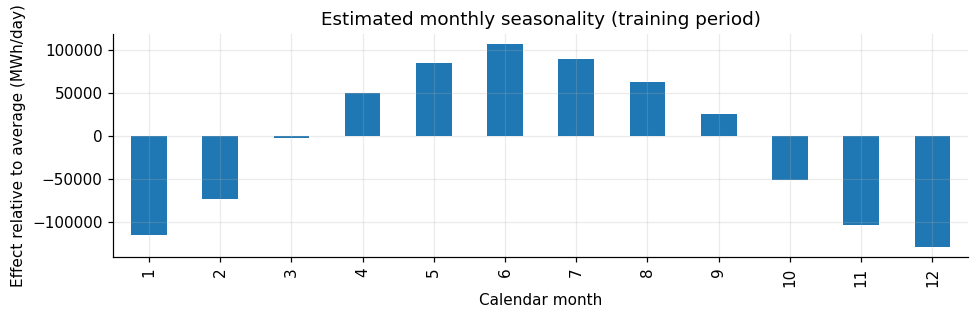

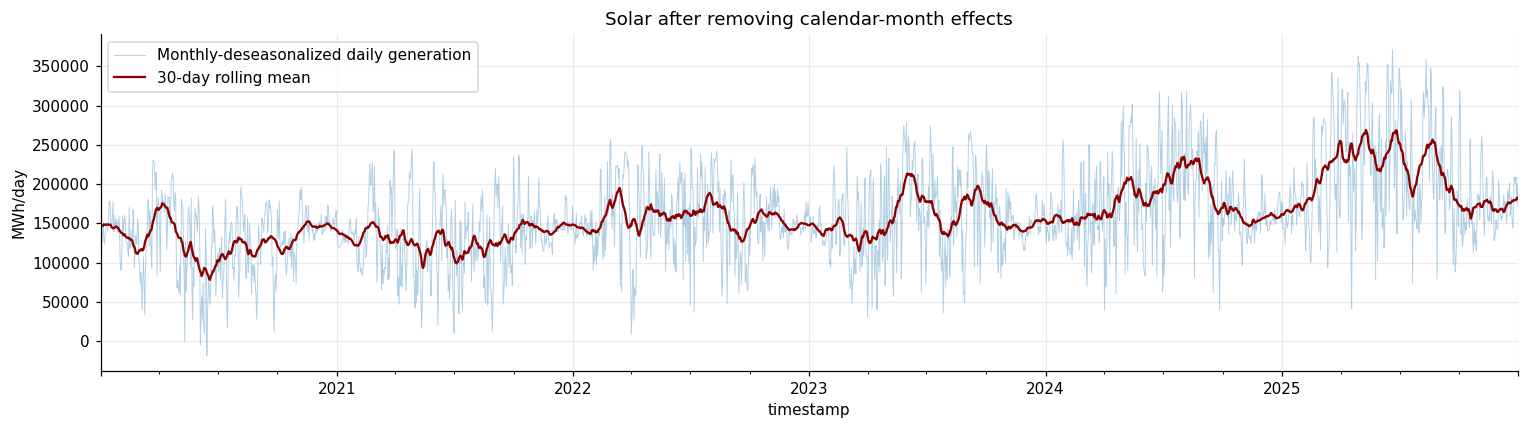

In [19]:
solar = daily_energy["Photovoltaics"].dropna().sort_index()

split = int(len(solar) * 0.8)
solar_train = solar.iloc[:split]

# 用本地日期计算经过的年数；不把柏林夏令时造成的 23/25 小时日误作日期偏移
def monthly_design(index):
    idx = pd.DatetimeIndex(index)
    dates = idx.tz_localize(None) if idx.tz is not None else idx
    origin = solar.index[0]
    origin = origin.tz_localize(None) if origin.tz is not None else origin

    t = np.asarray(
        (dates - origin).total_seconds() / 86400 / 365.2425
    )

    # 1 月作为参照月，加入 2–12 月指示变量
    month = idx.month.to_numpy()
    month_dummies = np.column_stack([
        (month == m).astype(float)
        for m in range(2, 13)
    ])

    return np.column_stack([
        np.ones(len(idx)),  # 截距
        t,                  # 长期线性趋势
        month_dummies,      # 2–12 月的月度效应
    ])

X_train = monthly_design(solar_train.index)
beta = np.linalg.lstsq(
    X_train,
    solar_train.to_numpy(),
    rcond=None,
)[0]

# 月份系数最初是相对于 1 月的；构造成 12 个月的季节效应
month_effect = np.r_[0.0, beta[2:]]

# 把季节效应中心化，让它表示相对平均水平的偏差
month_counts = np.bincount(
    solar_train.index.month,
    minlength=13,
)[1:13]
month_effect -= np.average(month_effect, weights=month_counts)

# 按每个日期所在的本地月份套用季节效应
seasonal_month = pd.Series(
    month_effect[solar.index.month - 1],
    index=solar.index,
    name="estimated_monthly_seasonality",
)

solar_monthly_deseasonalized = (
    solar - seasonal_month
).rename("solar_monthly_deseasonalized")

# 看模型估计的月度效应
pd.Series(
    month_effect,
    index=range(1, 13),
    name="seasonal_effect_MWh_per_day",
).plot(
    kind="bar",
    figsize=(9, 3),
    title="Estimated monthly seasonality (training period)",
)
plt.xlabel("Calendar month")
plt.ylabel("Effect relative to average (MWh/day)")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

# 看减去月度季节效应之后的数据
ax = solar_monthly_deseasonalized.plot(
    figsize=(14, 4),
    alpha=0.35,
    linewidth=0.6,
    label="Monthly-deseasonalized daily generation",
)
solar_monthly_deseasonalized.rolling(
    30, center=True, min_periods=15
).mean().plot(
    ax=ax,
    color="darkred",
    linewidth=1.5,
    label="30-day rolling mean",
)
ax.set_title("Solar after removing calendar-month effects")
ax.set_ylabel("MWh/day")
ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()